In [1]:
machine_rates = {
    "Flexo A": 112,
    "Flexo B": 224,
    "Flexo C": 175,
}

orders_data = [
    {"id": 1, "quantity": 16539, "inks": [6, 8]},
    {"id": 2, "quantity": 5020, "inks": [4, 5, 6]},
    {"id": 3, "quantity": 5110, "inks": [1, 2, 8]},
    {"id": 4, "quantity": 6030, "inks": [6, 6]},
    {"id": 5, "quantity": 6100, "inks": [9]},
    {"id": 6, "quantity": 24173, "inks": [6, 8, 9]},
    {"id": 7, "quantity": 15740, "inks": [2, 4, 6, 6]},
    {"id": 8, "quantity": 21165, "inks": [6, 4, 6]},
    {"id": 9, "quantity": 4640, "inks": [8]},
    {"id": 10, "quantity": 12100, "inks": [5, 8, 9]},
    {"id": 11, "quantity": 8000, "inks": [8, 9]},
    {"id": 12, "quantity": 14030, "inks": [6, 5, 6, 8]},
    {"id": 13, "quantity": 5180, "inks": [4, 8]},
    {"id": 14, "quantity": 9150, "inks": [9]},
    {"id": 15, "quantity": 23979, "inks": [7, 4, 6]},
]

job_batches = [
    {"arrival_time": 0, "orders": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]},
]

## Instance Generation

**Synthetic job generation (N=30, N=50):**
Bootstrap resampling from the 15 real orders — preserves quantity distribution and ink patterns. Quantities are perturbed ±15% to avoid exact duplicates.

**N=15 special case:** replication 0 uses the original `orders_data` verbatim; replications 1–9 are synthetic variants.

**Batching:**
- **Static (k=1):** All jobs arrive at $t=0$
- **2-batch / 3-batch:** Jobs randomly split into equal-sized batches. Batches arrive at deterministic (equal) intervals of $\bar{\Delta}$

**Arrival time formula:**
$$\bar{\Delta} = \frac{\bar{p} \cdot (N/k)}{\rho \cdot m}$$
where $\bar{p}$ = avg processing time per job (hours), $m$ = number of machines, $\rho$ = utilization/congestion level.

Higher $\rho$ → shorter gap → more congestion.

**Testing instances:** $3 \times (1 + 2 \times 2) \times 10 = 150$ (rep00–rep09)

**Tuning instances:** $3 \times (1 + 2 \times 2) \times 1 = 15$ one extra rep per instance type (saved to `instances/tuning/`)


In [2]:
import numpy as np
import json
import os

# ---------- parameters ----------
N_VALUES = [15, 30, 50, 100, 200]
RHO_VALUES = [1.0, 1.5]
N_REPS = 10
TUNE_REP = N_REPS  # rep index used for tuning instances (rep10)
SEED = 42


# ---------- synthetic job generation ----------
def generate_orders_for_rep(original_orders, n, rep, rng):
    """Generate orders for one replication.

    rep=0 and n==15: return original data verbatim (no perturbation).
    All other cases: bootstrap resample with ±15% quantity perturbation.
    """
    if rep == 0 and n == len(original_orders):
        return [o.copy() for o in original_orders]

    orders = []
    for i in range(n):
        template = original_orders[rng.integers(len(original_orders))]
        qty = int(template["quantity"] * rng.uniform(0.85, 1.15))
        qty = max(1000, qty)
        orders.append(
            {"id": i + 1, "quantity": qty, "inks": list(template["inks"])}
        )
    return orders


# ---------- deterministic inter-arrival gap ----------
def _deterministic_gap(orders, machine_rates, rho, num_batches):
    """Deterministic inter-arrival gap (hours) between successive batches."""
    avg_qty = np.mean([o["quantity"] for o in orders])
    avg_rate = np.mean(list(machine_rates.values()))  # pieces / min
    p_bar = avg_qty / avg_rate / 60                   # hours / job
    n_per_batch = len(orders) / num_batches
    m = len(machine_rates)
    return p_bar * n_per_batch / (rho * m)


def _build_instance_group(n, rep, orders, rng, label_fn):
    """Build one static + multi-batch group of instances for a given (N, rep)."""
    group = {}
    order_ids = [o["id"] for o in orders]

    # k=1: static — all jobs at t=0
    key = label_fn(n, 1, None, rep)
    group[key] = {
        "orders_data": orders,
        "job_batches": [{"arrival_time": 0, "orders": list(order_ids)}],
        "n": n, "k": 1, "rho": None, "rep": rep,
    }

    for k in [2, 3]:
        # ONE shuffle per (N, k, rep) — shared across both rho values
        shuffled = rng.permutation(order_ids).tolist()
        batch_size = n // k
        splits = []
        for i in range(k):
            lo = i * batch_size
            hi = n if i == k - 1 else lo + batch_size
            splits.append(sorted(shuffled[lo:hi]))

        for rho in RHO_VALUES:
            gap = _deterministic_gap(orders, machine_rates, rho, k)
            job_batches = [
                {"arrival_time": round(i * gap, 2), "orders": batch_orders}
                for i, batch_orders in enumerate(splits)
            ]
            key = label_fn(n, k, rho, rep)
            group[key] = {
                "orders_data": orders,
                "job_batches": job_batches,
                "n": n, "k": k, "rho": rho, "rep": rep,
            }
    return group


# ---------- generate all 150 testing instances ----------
rng = np.random.default_rng(SEED)

def testing_label(n, k, rho, rep):
    if k == 1:
        return f"N{n}_K1_static_rep{rep:02d}"
    return f"N{n}_K{k}_rho{rho}_rep{rep:02d}"

instances = {}
for n in N_VALUES:
    for rep in range(N_REPS):
        orders = generate_orders_for_rep(orders_data, n, rep, rng)
        instances.update(_build_instance_group(n, rep, orders, rng, testing_label))

# ---------- generate 15 tuning instances (one per instance type) ----------
def tuning_label(n, k, rho, rep):
    if k == 1:
        return f"N{n}_K1_static_tune"
    return f"N{n}_K{k}_rho{rho}_tune"

tuning_instances = {}
for n in N_VALUES:
    orders = generate_orders_for_rep(orders_data, n, TUNE_REP, rng)
    tuning_instances.update(_build_instance_group(n, TUNE_REP, orders, rng, tuning_label))

print(f"Generated {len(instances)} testing instances")
print(f"Generated {len(tuning_instances)} tuning instances\n")

print("--- Testing (sample) ---")
for key, inst in list(instances.items())[:5]:
    batches_str = "  |  ".join(
        f"t={b['arrival_time']:.2f}h ({len(b['orders'])} jobs)"
        for b in inst["job_batches"]
    )
    rho_str = f"rho={inst['rho']}" if inst["rho"] else "static"
    print(f"  {key:30s}  {rho_str:10s}  {batches_str}")

print("\n--- Tuning ---")
for key, inst in tuning_instances.items():
    batches_str = "  |  ".join(
        f"t={b['arrival_time']:.2f}h ({len(b['orders'])} jobs)"
        for b in inst["job_batches"]
    )
    rho_str = f"rho={inst['rho']}" if inst["rho"] else "static"
    print(f"  {key:30s}  {rho_str:10s}  {batches_str}")


Generated 250 testing instances
Generated 25 tuning instances

--- Testing (sample) ---
  N15_K1_static_rep00             static      t=0.00h (15 jobs)
  N15_K2_rho1.0_rep00             rho=1.0     t=0.00h (7 jobs)  |  t=2.89h (8 jobs)
  N15_K2_rho1.5_rep00             rho=1.5     t=0.00h (7 jobs)  |  t=1.92h (8 jobs)
  N15_K3_rho1.0_rep00             rho=1.0     t=0.00h (5 jobs)  |  t=1.92h (5 jobs)  |  t=3.85h (5 jobs)
  N15_K3_rho1.5_rep00             rho=1.5     t=0.00h (5 jobs)  |  t=1.28h (5 jobs)  |  t=2.57h (5 jobs)

--- Tuning ---
  N15_K1_static_tune              static      t=0.00h (15 jobs)
  N15_K2_rho1.0_tune              rho=1.0     t=0.00h (7 jobs)  |  t=3.27h (8 jobs)
  N15_K2_rho1.5_tune              rho=1.5     t=0.00h (7 jobs)  |  t=2.18h (8 jobs)
  N15_K3_rho1.0_tune              rho=1.0     t=0.00h (5 jobs)  |  t=2.18h (5 jobs)  |  t=4.36h (5 jobs)
  N15_K3_rho1.5_tune              rho=1.5     t=0.00h (5 jobs)  |  t=1.45h (5 jobs)  |  t=2.91h (5 jobs)
  N30_K1_sta

In [3]:
import pandas as pd

def _instances_to_rows(inst_dict, split_label):
    rows = []
    for key, inst in inst_dict.items():
        for i, b in enumerate(inst["job_batches"]):
            rows.append({
                "instance": key,
                "split": split_label,
                "N": inst["n"],
                "batches (k)": inst["k"],
                "rho": inst["rho"] if inst["rho"] else "—",
                "rep": inst["rep"],
                "batch #": i + 1,
                "arrival_time (h)": b["arrival_time"],
                "jobs_in_batch": len(b["orders"]),
            })
    return rows

rows = _instances_to_rows(instances, "testing") + _instances_to_rows(tuning_instances, "tuning")
df_summary = pd.DataFrame(rows)
print(df_summary["split"].value_counts().to_string())
df_summary


split
testing    550
tuning      55


,instance,split,N,batches (k),rho,rep,batch #,arrival_time (h),jobs_in_batch
0,N15_K1_static_rep00,testing,15,1,—,0,1,0.00,15
1,N15_K2_rho1.0_rep00,testing,15,2,1.0,0,1,0.00,7
2,N15_K2_rho1.0_rep00,testing,15,2,1.0,0,2,2.89,8
3,N15_K2_rho1.5_rep00,testing,15,2,1.5,0,1,0.00,7
4,N15_K2_rho1.5_rep00,testing,15,2,1.5,0,2,1.92,8
...,...,...,...,...,...,...,...,...,...
600,N200_K3_rho1.0_tune,tuning,200,3,1.0,10,2,26.68,66
601,N200_K3_rho1.0_tune,tuning,200,3,1.0,10,3,53.36,68
602,N200_K3_rho1.5_tune,tuning,200,3,1.5,10,1,0.00,66
603,N200_K3_rho1.5_tune,tuning,200,3,1.5,10,2,17.79,66


In [4]:
# ---------- save all testing instances to JSON ----------
os.makedirs("instances", exist_ok=True)

for key, inst in instances.items():
    payload = {
        "machine_rates": machine_rates,
        "orders_data": inst["orders_data"],
        "job_batches": inst["job_batches"],
        "meta": {"n": inst["n"], "k": inst["k"], "rho": inst["rho"], "rep": inst["rep"]},
    }
    path = os.path.join("instances", f"{key}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)

print(f"Saved {len(instances)} testing instance files to instances/")

# ---------- save all tuning instances to JSON ----------
os.makedirs("instances/tuning", exist_ok=True)

for key, inst in tuning_instances.items():
    payload = {
        "machine_rates": machine_rates,
        "orders_data": inst["orders_data"],
        "job_batches": inst["job_batches"],
        "meta": {"n": inst["n"], "k": inst["k"], "rho": inst["rho"], "rep": inst["rep"], "split": "tuning"},
    }
    path = os.path.join("instances", "tuning", f"{key}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)

print(f"Saved {len(tuning_instances)} tuning instance files to instances/tuning/")


Saved 250 testing instance files to instances/
Saved 25 tuning instance files to instances/tuning/


In [5]:
# ---------- spot-check ----------
print("N15 static: rep00 (should be original), rep01 (should be synthetic)")
for rep in [0, 1]:
    inst = instances[f"N15_K1_static_rep{rep:02d}"]
    qs = [o["quantity"] for o in inst["orders_data"]]
    print(f"  rep{rep:02d}  quantities: {qs}")

print("\nN15 K2 rho0.8 vs rho0.95 rep00 (same job split, different gaps):")
for rho in [1.0, 1.5]:
    inst = instances[f"N15_K2_rho{rho}_rep00"]
    batches = inst["job_batches"]
    print(f"  rho={rho}  {[b['arrival_time'] for b in batches]}  jobs_per_batch={[len(b['orders']) for b in batches]}")

N15 static: rep00 (should be original), rep01 (should be synthetic)
  rep00  quantities: [16539, 5020, 5110, 6030, 6100, 24173, 15740, 21165, 4640, 12100, 8000, 14030, 5180, 9150, 23979]
  rep01  quantities: [10049, 17192, 4886, 16011, 17054, 8311, 20864, 18969, 15060, 9122, 15128, 6044, 12472, 5072, 6410]

N15 K2 rho0.8 vs rho0.95 rep00 (same job split, different gaps):
  rho=1.0  [np.float64(0.0), np.float64(2.89)]  jobs_per_batch=[7, 8]
  rho=1.5  [np.float64(0.0), np.float64(1.92)]  jobs_per_batch=[7, 8]


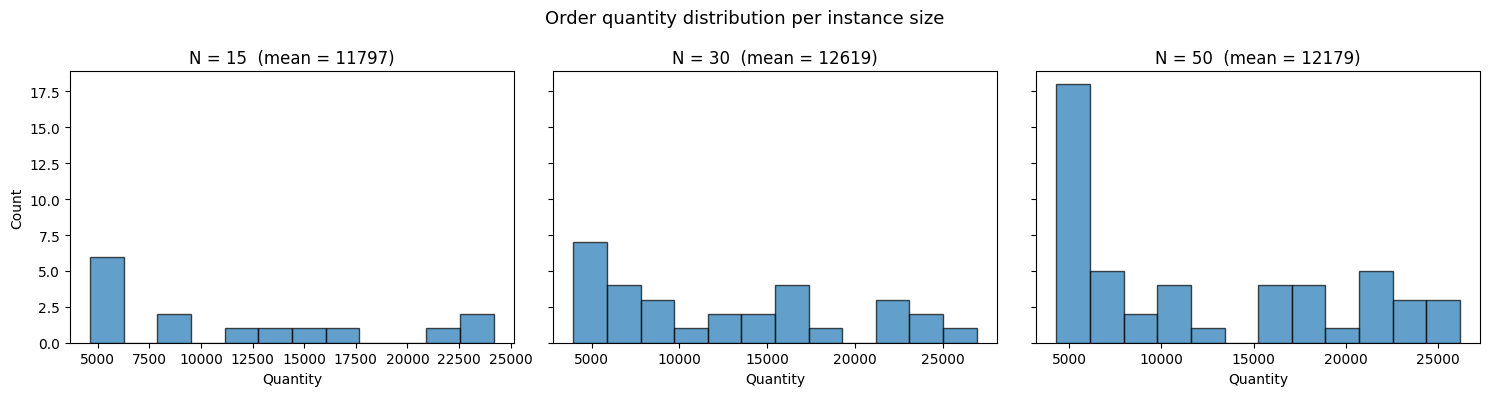

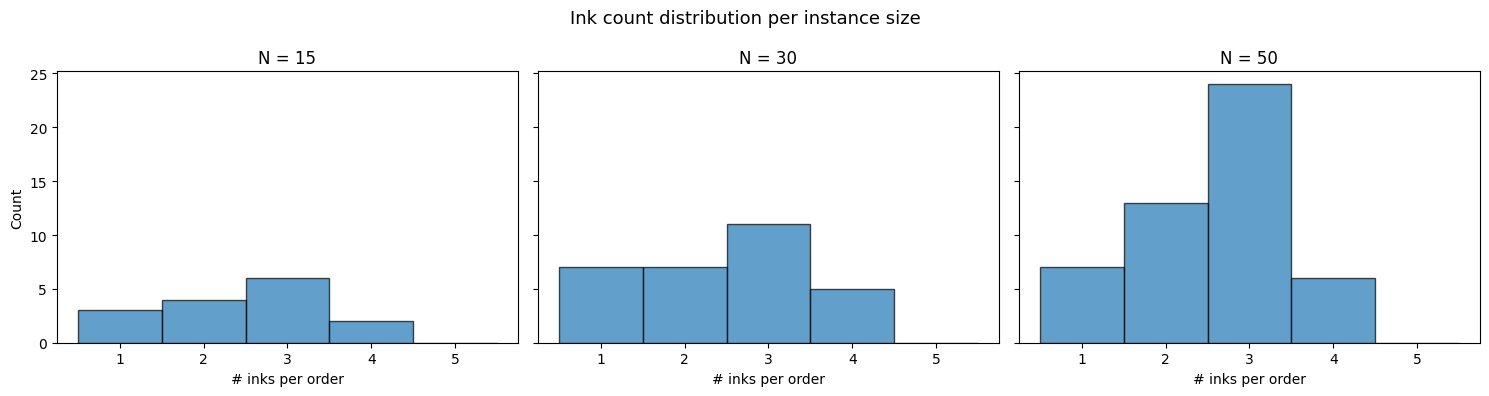

In [6]:
import matplotlib.pyplot as plt

# Build representative orders per N from existing generated instances
orders_by_n = {}
for n in N_VALUES:
    static_keys = sorted(
        [k for k, inst in instances.items() if inst["n"] == n and inst["k"] == 1],
        key=lambda k: instances[k]["rep"],
    )
    if not static_keys:
        raise ValueError(f"No static instance found for N={n}")
    orders_by_n[n] = instances[static_keys[0]]["orders_data"]

# ---------- sanity check: quantity distributions ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes, N_VALUES):
    qtys = [o["quantity"] for o in orders_by_n[n]]
    ax.hist(qtys, bins=12, edgecolor="black", alpha=0.7)
    ax.set_title(f"N = {n}  (mean = {np.mean(qtys):.0f})")
    ax.set_xlabel("Quantity")
axes[0].set_ylabel("Count")
fig.suptitle("Order quantity distribution per instance size", fontsize=13)
plt.tight_layout()
plt.show()

# ---------- sanity check: ink-count distributions ----------
fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes2, N_VALUES):
    ink_counts = [len(o["inks"]) for o in orders_by_n[n]]
    ax.hist(ink_counts, bins=range(1, 7), edgecolor="black", alpha=0.7, align="left")
    ax.set_title(f"N = {n}")
    ax.set_xlabel("# inks per order")
axes2[0].set_ylabel("Count")
fig2.suptitle("Ink count distribution per instance size", fontsize=13)
plt.tight_layout()
plt.show()